# How much does bad input data change a model's predictions?

This notebook corrupts the **test data** of a trained model in realistic ways and measures two things for each corruption:

1. **Impact:** how much the model's predictions change (AUC drop, share of predictions that flip).
2. **Detectability:** whether common data checks would have flagged the corrupted batch.

The question behind it: *which data errors hurt the model most while slipping past the checks most teams already run?*

**Dataset:** Default of Credit Card Clients, UCI Machine Learning Repository. Yeh, I. (2009), https://doi.org/10.24432/C55S3H. Licensed under CC BY 4.0.

**Steps:** configuration → load data → clean undocumented codes → train two models → define corruptions → define checks → run the experiment → summarise and chart.

In [1]:
! pip install ucimlrepo scikit-learn pandas matplotlib

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------------------------------------- - 8.1/8.4 MB 39.6 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 36.2 MB/s  0:00:00
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ------------------------------------ --- 10.0/10.9 MB 48.7 MB/s eta 0:00:01
   ---------------------------------------- 10.9/10.9 MB 41.6 MB/s  0:00:00
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------------------------- -------- 7.6/9.5 MB 35.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 33.6 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 36.0 MB/s  0:00:00
   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ----------------------- ---------------- 7.6/12.7 MB 36.2 MB/s eta 0:00:01
   ---------------------------------------- 

## 1. Configuration

In [37]:
from pathlib import Path

SEED = 42
SEVERITIES = [0.05, 0.20, 0.50]  # share of test rows corrupted
N_REPEATS = 10                     # repeats per corruption and severity, each with a different random seed
THRESHOLD = 0.5                   # probability threshold used to decide whether a prediction flipped

# "uci" downloads the data with ucimlrepo; "file" reads LOCAL_PATH (.xls, .xlsx or .csv)
DATA_SOURCE = "uci"
LOCAL_PATH = "default of credit card clients.xls"

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [38]:
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Record versions: results can shift between library versions
print(f"Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}, "
      f"scikit-learn {sklearn.__version__}, matplotlib {matplotlib.__version__}")

Python 3.15.2, pandas 3.1.1, numpy 2.5.4, scikit-learn 1.9.1, matplotlib 3.11.2


## 2. Load the data

`ucimlrepo` returns the features as `X1` to `X23`. They're renamed to the descriptive names used in the original file.
Bill and payment columns run from the most recent month (September 2005, suffix 1) back to April 2005 (suffix 6).
The repayment status columns are named `PAY_0`, `PAY_2` … `PAY_6`, as in the original file (there is no `PAY_1`).

In [39]:
X_NAMES = {
    "X1": "LIMIT_BAL", "X2": "SEX", "X3": "EDUCATION", "X4": "MARRIAGE", "X5": "AGE",
    "X6": "PAY_0", "X7": "PAY_2", "X8": "PAY_3", "X9": "PAY_4", "X10": "PAY_5", "X11": "PAY_6",
    "X12": "BILL_AMT1", "X13": "BILL_AMT2", "X14": "BILL_AMT3",
    "X15": "BILL_AMT4", "X16": "BILL_AMT5", "X17": "BILL_AMT6",
    "X18": "PAY_AMT1", "X19": "PAY_AMT2", "X20": "PAY_AMT3",
    "X21": "PAY_AMT4", "X22": "PAY_AMT5", "X23": "PAY_AMT6",
}
FEATURES = list(X_NAMES.values())
TARGET_NAMES = {"y", "default payment next month", "default.payment.next.month", "default"}


def load_credit_default(source: str, path: str | None = None) -> tuple[pd.DataFrame, pd.Series]:
    if source == "uci":
        from ucimlrepo import fetch_ucirepo

        dataset = fetch_ucirepo(id=350)
        X = dataset.data.features.copy()
        y = dataset.data.targets.iloc[:, 0].copy()
    elif source == "file":
        path = Path(path)
        # The original .xls has a first header row of X1..X23 labels, so the real names are on row 2
        raw = pd.read_excel(path, header=1) if path.suffix in {".xls", ".xlsx"} else pd.read_csv(path)
        target_cols = [c for c in raw.columns if str(c).strip().lower() in TARGET_NAMES]
        if len(target_cols) != 1:
            raise ValueError(f"Expected one target column, found {target_cols}")
        y = raw[target_cols[0]]
        X = raw.drop(columns=target_cols + [c for c in raw.columns if str(c).upper() == "ID"])
    else:
        raise ValueError("DATA_SOURCE must be 'uci' or 'file'")

    X = X.rename(columns=X_NAMES)
    missing = set(FEATURES) - set(X.columns)
    if missing:
        raise ValueError(f"Missing expected columns: {sorted(missing)}")

    # Float everywhere so every column can hold NaN after corruption
    X = X[FEATURES].astype(float)
    y = y.astype(int).rename("default")
    return X, y


X, y = load_credit_default(DATA_SOURCE, LOCAL_PATH)
print(f"{len(X):,} rows, {X.shape[1]} features; default rate {y.mean():.1%}")
X.head()

30,000 rows, 23 features; default rate 22.1%


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000.0,2.0,2.0,1.0,24.0,2.0,2.0,-1.0,-1.0,-2.0,...,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0
1,120000.0,2.0,2.0,2.0,26.0,-1.0,2.0,0.0,0.0,0.0,...,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0
2,90000.0,2.0,2.0,2.0,34.0,0.0,0.0,0.0,0.0,0.0,...,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0
3,50000.0,2.0,2.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0
4,50000.0,1.0,2.0,1.0,57.0,-1.0,0.0,-1.0,0.0,0.0,...,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0


## 3. Clean undocumented codes

The documentation lists education codes 1–4 and marital status codes 1–3, but the data contains other values.
They're mapped to the "other" category here. Check the counts below, and state this choice in the article.

In [40]:
print("EDUCATION before:", X["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE before: ", X["MARRIAGE"].value_counts().sort_index().to_dict())

X["EDUCATION"] = X["EDUCATION"].where(X["EDUCATION"].isin([1, 2, 3, 4]), 4)
X["MARRIAGE"] = X["MARRIAGE"].where(X["MARRIAGE"].isin([1, 2, 3]), 3)

print("EDUCATION after: ", X["EDUCATION"].value_counts().sort_index().to_dict())
print("MARRIAGE after:  ", X["MARRIAGE"].value_counts().sort_index().to_dict())

EDUCATION before: {0.0: 14, 1.0: 10585, 2.0: 14030, 3.0: 4917, 4.0: 123, 5.0: 280, 6.0: 51}
MARRIAGE before:  {0.0: 54, 1.0: 13659, 2.0: 15964, 3.0: 323}
EDUCATION after:  {1.0: 10585, 2.0: 14030, 3.0: 4917, 4.0: 468}
MARRIAGE after:   {1.0: 13659, 2.0: 15964, 3.0: 377}


## 4. Train two models

Two common choices that handle bad data differently:

- **Gradient boosting** (`HistGradientBoostingClassifier`) handles missing values natively and treats codes as numbers.
- **Logistic regression** fills missing values with the training median and one-hot encodes the categorical codes.

The test set is the "serving data" that gets corrupted later. Only the test set is ever corrupted; the models are trained once on clean data.

In [41]:
CATEGORICAL = ["SEX", "EDUCATION", "MARRIAGE"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)

logistic = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), NUMERIC),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), CATEGORICAL),
    ])),
    ("model", LogisticRegression(max_iter=2000)),
])

MODELS = {
    "gradient_boosting": HistGradientBoostingClassifier(random_state=SEED),
    "logistic_regression": logistic,
}

clean_proba = {}
for name, model in MODELS.items():
    model.fit(X_train, y_train)
    clean_proba[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name:20s} clean test AUC = {roc_auc_score(y_test, clean_proba[name]):.3f}")

gradient_boosting    clean test AUC = 0.777
logistic_regression  clean test AUC = 0.716


## 5. Corruptions

Each corruption takes a clean test batch and returns a corrupted copy, changing a share of rows set by the severity.
Each one mimics a pipeline bug that produces values that still *look* valid.

In [42]:
TRAIN_MEDIAN = X_train.median()


def pick_rows(df, frac, rng):
    n = int(round(frac * len(df)))
    return df.index[rng.choice(len(df), size=n, replace=False)]


def random_missing(col):
    def corrupt(df, frac, rng):
        out = df.copy()
        out.loc[pick_rows(out, frac, rng), col] = np.nan
        return out
    return corrupt


def missing_high(col):
    # Values go missing mainly at the top end, e.g. a source system that drops large amounts
    def corrupt(df, frac, rng):
        out = df.copy()
        n = int(round(frac * len(out)))
        top = out[col].sort_values(ascending=False).index[:n]
        out.loc[top, col] = np.nan
        return out
    return corrupt


def set_to_zero(col):
    # Missing values silently filled with 0 upstream
    def corrupt(df, frac, rng):
        out = df.copy()
        out.loc[pick_rows(out, frac, rng), col] = 0.0
        return out
    return corrupt


def rescale(col, factor):
    def corrupt(df, frac, rng):
        out = df.copy()
        rows = pick_rows(out, frac, rng)
        out.loc[rows, col] = out.loc[rows, col] * factor
        return out
    return corrupt


def swap(col_a, col_b):
    def corrupt(df, frac, rng):
        out = df.copy()
        rows = pick_rows(out, frac, rng)
        out.loc[rows, [col_a, col_b]] = out.loc[rows, [col_b, col_a]].to_numpy()
        return out
    return corrupt


def copy_from(source, target):
    # A stale feed: this month's value is last month's value
    def corrupt(df, frac, rng):
        out = df.copy()
        rows = pick_rows(out, frac, rng)
        out.loc[rows, target] = out.loc[rows, source]
        return out
    return corrupt


def remap_codes(col, mapping):
    def corrupt(df, frac, rng):
        out = df.copy()
        rows = pick_rows(out, frac, rng)
        out.loc[rows, col] = out.loc[rows, col].replace(mapping)
        return out
    return corrupt


def freeze(col, value):
    def corrupt(df, frac, rng):
        out = df.copy()
        out.loc[pick_rows(out, frac, rng), col] = value
        return out
    return corrupt


def add_noise(col, relative_sd):
    def corrupt(df, frac, rng):
        out = df.copy()
        rows = pick_rows(out, frac, rng)
        out.loc[rows, col] = out.loc[rows, col] + rng.normal(0, relative_sd * df[col].std(), len(rows))
        return out
    return corrupt


CORRUPTIONS = {
    "Random missing: AGE": random_missing("AGE"),
    "Missing at the high end: LIMIT_BAL": missing_high("LIMIT_BAL"),
    "Missing payments filled with 0: PAY_AMT1": set_to_zero("PAY_AMT1"),
    "Limit sent in thousands: LIMIT_BAL": rescale("LIMIT_BAL", 1 / 1000),
    "Bill months swapped: BILL_AMT1/BILL_AMT2": swap("BILL_AMT1", "BILL_AMT2"),
    "Stale bill: BILL_AMT1 = BILL_AMT2": copy_from("BILL_AMT2", "BILL_AMT1"),
    "Stale repayment status: PAY_0 = PAY_2": copy_from("PAY_2", "PAY_0"),
    "Sex codes swapped: SEX": remap_codes("SEX", {1.0: 2.0, 2.0: 1.0}),
    "Frozen at training median: LIMIT_BAL": freeze("LIMIT_BAL", TRAIN_MEDIAN["LIMIT_BAL"]),
    "Small noise (10% of SD): BILL_AMT1": add_noise("BILL_AMT1", 0.10),
}
print(f"{len(CORRUPTIONS)} corruptions defined")

10 corruptions defined


## 6. Checks

Two tiers of checks, both built from the **training data** as the reference:

- **Basic checks**, the ones most teams already run: schema (columns present), null rate, value range, and allowed codes for categorical and status columns.
  The range check flags a batch only when more than 1% of a column's values fall outside the training minimum and maximum. Payment amounts have long tails, so a strict "any value outside the range" rule fires on clean data too.
- **Distribution check:** Population Stability Index (PSI) per column against the training distribution. A PSI above 0.2 is a common rule of thumb for a meaningful shift.

All checks run on the whole corrupted batch, as they would in a pipeline, and don't know which rows were corrupted.

In [43]:
CODE_COLUMNS = CATEGORICAL + ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
NULL_TOLERANCE = 0.01   # flag if the null rate rises more than 1 percentage point
RANGE_TOLERANCE = 0.01  # flag if more than 1% of values fall outside the training min-max
PSI_THRESHOLD = 0.2
PSI_BINS = 10
EPS = 1e-6


def build_profile(reference: pd.DataFrame) -> dict:
    profile = {
        "columns": list(reference.columns),
        "null_rate": reference.isna().mean(),
        "min": reference.min(),
        "max": reference.max(),
        "allowed": {c: set(reference[c].dropna().unique()) for c in CODE_COLUMNS},
        "bins": {},
        "expected_shares": {},
    }
    for col in reference.columns:
        if col in CODE_COLUMNS:
            shares = reference[col].value_counts(normalize=True)
            profile["expected_shares"][col] = shares
        else:
            edges = np.unique(np.quantile(reference[col].dropna(), np.linspace(0, 1, PSI_BINS + 1)))
            edges[0], edges[-1] = -np.inf, np.inf
            profile["bins"][col] = edges
            counts = pd.cut(reference[col], edges, include_lowest=True).value_counts(normalize=True, sort=False)
            profile["expected_shares"][col] = counts
    return profile


def psi(expected: pd.Series, actual: pd.Series) -> float:
    expected, actual = expected.align(actual, fill_value=0)
    expected, actual = expected + EPS, actual + EPS
    return float(((actual - expected) * np.log(actual / expected)).sum())


def run_checks(profile: dict, batch: pd.DataFrame) -> dict:
    flagged = {"schema": [], "nulls": [], "range": [], "allowed_values": [], "psi": []}

    if list(batch.columns) != profile["columns"]:
        flagged["schema"].append("columns differ")

    null_rate = batch.isna().mean()
    flagged["nulls"] = [c for c in batch.columns if null_rate[c] > profile["null_rate"][c] + NULL_TOLERANCE]

    for col in batch.columns:
        values = batch[col].dropna()
        outside = ((values < profile["min"][col]) | (values > profile["max"][col])).mean() if len(values) else 0.0
        if outside > RANGE_TOLERANCE:
            flagged["range"].append(col)

    for col in CODE_COLUMNS:
        if not set(batch[col].dropna().unique()) <= profile["allowed"][col]:
            flagged["allowed_values"].append(col)

    for col in batch.columns:
        values = batch[col].dropna()
        if col in CODE_COLUMNS:
            actual = values.value_counts(normalize=True)
        else:
            actual = pd.cut(values, profile["bins"][col], include_lowest=True).value_counts(normalize=True, sort=False)
        if psi(profile["expected_shares"][col], actual) > PSI_THRESHOLD:
            flagged["psi"].append(col)

    flagged["caught_by_basic"] = any(flagged[k] for k in ["schema", "nulls", "range", "allowed_values"])
    flagged["caught_by_psi"] = bool(flagged["psi"])
    return flagged


PROFILE = build_profile(X_train)

# Sanity check: the clean test set should pass every check
clean_result = run_checks(PROFILE, X_test)
print({k: v for k, v in clean_result.items()})
assert not clean_result["caught_by_basic"] and not clean_result["caught_by_psi"], "Clean data should pass all checks"

{'schema': [], 'nulls': [], 'range': [], 'allowed_values': [], 'psi': [], 'caught_by_basic': False, 'caught_by_psi': False}


## 6b. Two more checks aimed at the danger zone

The first run showed that some corruptions, especially a **stale repayment status**, change many predictions while passing every check above.
Two extra checks target that gap:

- **Month-over-month consistency.** For consecutive months (for example `PAY_0` and `PAY_2`), compare the share of rows where this month **equals** last month, and the share where it went **up**, with the same shares in the training data. A stale feed pushes the "equal" share up; swapped months change the "up" share. A batch is flagged when a share differs from training by more than `Z_THRESHOLD` standard errors.
- **Prediction drift.** Compare the distribution of the model's **output probabilities** with a reference distribution, using PSI. This watches the model's behaviour rather than its inputs, so it can react whatever the cause. The reference comes from out-of-fold predictions on the training data, so it reflects how the model scores data it hasn't seen.

In [44]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict

PAIRS = [("PAY_0", "PAY_2"), ("BILL_AMT1", "BILL_AMT2"), ("PAY_AMT1", "PAY_AMT2")]
Z_THRESHOLD = 4.0               # standard errors; high on purpose to keep false alarms rare
PREDICTION_PSI_THRESHOLD = 0.1  # a common "moderate shift" level for model scores


def pair_shares(df: pd.DataFrame, a: str, b: str) -> tuple[dict, int]:
    valid = df[[a, b]].dropna()
    return {"equal": float((valid[a] == valid[b]).mean()), "up": float((valid[a] > valid[b]).mean())}, len(valid)


def build_pair_profile(reference: pd.DataFrame) -> dict:
    return {(a, b): pair_shares(reference, a, b)[0] for a, b in PAIRS}


def run_consistency_checks(pair_profile: dict, batch: pd.DataFrame) -> list[str]:
    flagged = []
    for (a, b), reference in pair_profile.items():
        shares, n = pair_shares(batch, a, b)
        for stat in ("equal", "up"):
            p = reference[stat]
            se = np.sqrt(max(p * (1 - p), 1e-9) / max(n, 1))
            if abs(shares[stat] - p) / se > Z_THRESHOLD:
                flagged.append(f"{a} vs {b} share {stat}: {p:.1%} -> {shares[stat]:.1%}")
    return flagged


def score_bins(reference_scores: np.ndarray) -> np.ndarray:
    edges = np.unique(np.quantile(reference_scores, np.linspace(0, 1, PSI_BINS + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return edges


def score_shares(scores: np.ndarray, edges: np.ndarray) -> pd.Series:
    return pd.cut(pd.Series(scores), edges, include_lowest=True).value_counts(normalize=True, sort=False)


PAIR_PROFILE = build_pair_profile(X_train)
for (a, b), shares in PAIR_PROFILE.items():
    print(f"Training: {a} = {b} in {shares['equal']:.1%} of rows; {a} > {b} in {shares['up']:.1%}")

# Reference score distribution: out-of-fold predictions on the training data
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORE_REFERENCE = {}
for name, model in MODELS.items():
    oof = cross_val_predict(clone(model), X_train, y_train, cv=folds, method="predict_proba")[:, 1]
    edges = score_bins(oof)
    SCORE_REFERENCE[name] = {"edges": edges, "shares": score_shares(oof, edges)}

# Sanity checks: clean test data should pass both new checks
assert not run_consistency_checks(PAIR_PROFILE, X_test), "Clean data should pass the consistency check"
for name in MODELS:
    clean_psi = psi(SCORE_REFERENCE[name]["shares"], score_shares(clean_proba[name], SCORE_REFERENCE[name]["edges"]))
    print(f"{name:20s} prediction PSI on clean test data = {clean_psi:.3f}")
    assert clean_psi <= PREDICTION_PSI_THRESHOLD, f"Clean predictions already drift for {name}"

Training: PAY_0 = PAY_2 in 77.0% of rows; PAY_0 > PAY_2 in 12.4%
Training: BILL_AMT1 = BILL_AMT2 in 8.7% of rows; BILL_AMT1 > BILL_AMT2 in 43.9%
Training: PAY_AMT1 = PAY_AMT2 in 15.6% of rows; PAY_AMT1 > PAY_AMT2 in 44.4%
gradient_boosting    prediction PSI on clean test data = 0.012
logistic_regression  prediction PSI on clean test data = 0.001


## 7. Run the experiment

For every corruption, severity and repeat: corrupt the test batch, run the input checks once, then score both models and run the prediction-drift check for each.

Impact:
- `auc_drop`: clean AUC minus corrupted AUC (higher is worse)
- `flip_rate_corrupted`: share of *changed rows* whose predicted class flipped at `THRESHOLD`
- `mean_abs_change`: average change in predicted probability across all rows

Direction of the flips (counts on changed rows):
- `flips_to_low_risk`: predicted default on clean data, no default on corrupted data — **risk the model no longer sees**
- `flips_to_high_risk`: the reverse — **false alarms**
- `defaulters_newly_missed` / `defaulters_newly_caught`: the same, restricted to customers who actually defaulted

In [45]:
def changed_rows(clean: pd.DataFrame, corrupted: pd.DataFrame) -> pd.Series:
    both_nan = clean.isna() & corrupted.isna()
    return ((clean != corrupted) & ~both_nan).any(axis=1)


clean_auc = {name: roc_auc_score(y_test, p) for name, p in clean_proba.items()}
clean_class = {name: p >= THRESHOLD for name, p in clean_proba.items()}
defaulted = y_test.to_numpy() == 1
records = []

for c_index, (corruption, corrupt) in enumerate(CORRUPTIONS.items()):
    for severity in SEVERITIES:
        for repeat in range(N_REPEATS):
            rng = np.random.default_rng([SEED, c_index, int(severity * 100), repeat])
            batch = corrupt(X_test, severity, rng)
            mask = changed_rows(X_test, batch).to_numpy()
            checks = run_checks(PROFILE, batch)
            consistency = run_consistency_checks(PAIR_PROFILE, batch)

            for name, model in MODELS.items():
                proba = model.predict_proba(batch)[:, 1]
                new_class = proba >= THRESHOLD
                to_low = clean_class[name] & ~new_class
                to_high = ~clean_class[name] & new_class
                ref = SCORE_REFERENCE[name]
                prediction_psi = psi(ref["shares"], score_shares(proba, ref["edges"]))

                records.append({
                    "corruption": corruption,
                    "severity": severity,
                    "repeat": repeat,
                    "model": name,
                    "rows_changed": int(mask.sum()),
                    "auc": roc_auc_score(y_test, proba),
                    "auc_drop": clean_auc[name] - roc_auc_score(y_test, proba),
                    "flip_rate_corrupted": (to_low | to_high)[mask].mean() if mask.any() else 0.0,
                    "mean_abs_change": float(np.abs(proba - clean_proba[name]).mean()),
                    "flips_to_low_risk": int(to_low[mask].sum()),
                    "flips_to_high_risk": int(to_high[mask].sum()),
                    "defaulters_newly_missed": int((to_low & defaulted)[mask].sum()),
                    "defaulters_newly_caught": int((to_high & defaulted)[mask].sum()),
                    "caught_by_basic": checks["caught_by_basic"],
                    "caught_by_psi": checks["caught_by_psi"],
                    "caught_by_consistency": bool(consistency),
                    "prediction_psi": prediction_psi,
                    "caught_by_prediction_drift": prediction_psi > PREDICTION_PSI_THRESHOLD,
                    "checks_flagged": "; ".join(
                        [f"{k}: {', '.join(v)}" for k, v in checks.items() if isinstance(v, list) and v]
                        + [f"consistency: {c}" for c in consistency]
                    ),
                })

results = pd.DataFrame(records)
results.to_csv(OUTPUT_DIR / "results.csv", index=False)
print(f"{len(results):,} result rows saved to {OUTPUT_DIR / 'results.csv'}")

600 result rows saved to outputs\results.csv


## 8. Summarise

At 20% severity, averaged over repeats. The `caught_by_*` columns show the share of repeats in which each check fired.

In [46]:
DETECTION_ORDER = [
    "Caught by basic checks",
    "Caught only by distribution check",
    "Caught only by new checks",
    "Missed by all checks",
]


def detection_label(row) -> str:
    if row["caught_by_basic"] >= 0.5:
        return DETECTION_ORDER[0]
    if row["caught_by_psi"] >= 0.5:
        return DETECTION_ORDER[1]
    if row["caught_by_consistency"] >= 0.5 or row["caught_by_prediction_drift"] >= 0.5:
        return DETECTION_ORDER[2]
    return DETECTION_ORDER[3]


summary = (
    results[results["severity"] == 0.20]
    .groupby(["corruption", "model"])
    .agg(
        auc_drop=("auc_drop", "mean"),
        flip_rate_corrupted=("flip_rate_corrupted", "mean"),
        caught_by_basic=("caught_by_basic", "mean"),
        caught_by_psi=("caught_by_psi", "mean"),
        caught_by_consistency=("caught_by_consistency", "mean"),
        caught_by_prediction_drift=("caught_by_prediction_drift", "mean"),
    )
    .reset_index()
)
summary["detection"] = summary.apply(detection_label, axis=1)
summary = summary.sort_values(["model", "flip_rate_corrupted"], ascending=[True, False])
summary.to_csv(OUTPUT_DIR / "summary_20pct.csv", index=False)
summary.style.format({
    "auc_drop": "{:.4f}", "flip_rate_corrupted": "{:.1%}",
    "caught_by_basic": "{:.0%}", "caught_by_psi": "{:.0%}",
    "caught_by_consistency": "{:.0%}", "caught_by_prediction_drift": "{:.0%}",
})

,corruption,model,auc_drop,flip_rate_corrupted,caught_by_basic,caught_by_psi,caught_by_consistency,caught_by_prediction_drift,detection
18,Stale repayment status: PAY_0 = PAY_2,gradient_boosting,0.0062,35.9%,0%,0%,100%,0%,Caught only by new checks
4,Limit sent in thousands: LIMIT_BAL,gradient_boosting,0.0042,1.3%,100%,0%,0%,0%,Caught by basic checks
2,Frozen at training median: LIMIT_BAL,gradient_boosting,0.0026,0.5%,0%,100%,0%,0%,Caught only by distribution check
14,Small noise (10% of SD): BILL_AMT1,gradient_boosting,0.0007,0.4%,0%,0%,100%,0%,Caught only by new checks
16,Stale bill: BILL_AMT1 = BILL_AMT2,gradient_boosting,0.0008,0.4%,0%,0%,100%,0%,Caught only by new checks
8,Missing payments filled with 0: PAY_AMT1,gradient_boosting,0.0008,0.3%,0%,0%,100%,0%,Caught only by new checks
0,Bill months swapped: BILL_AMT1/BILL_AMT2,gradient_boosting,0.0003,0.3%,0%,0%,0%,0%,Missed by all checks
10,Random missing: AGE,gradient_boosting,0.0001,0.2%,100%,0%,0%,0%,Caught by basic checks
12,Sex codes swapped: SEX,gradient_boosting,0.0003,0.1%,0%,0%,0%,0%,Missed by all checks
6,Missing at the high end: LIMIT_BAL,gradient_boosting,0.0030,0.1%,100%,100%,0%,0%,Caught by basic checks


### Which way do the predictions flip?

At 20% severity, averaged over repeats. For a lender, `flips_to_low_risk` and `defaulters_newly_missed` are the costly direction: customers who now look safer than they are.

In [47]:
direction = (
    results[results["severity"] == 0.20]
    .groupby(["corruption", "model"])[
        ["rows_changed", "flips_to_low_risk", "flips_to_high_risk",
         "defaulters_newly_missed", "defaulters_newly_caught"]
    ]
    .mean()
    .round(1)
    .reset_index()
)
direction["total_flips"] = direction["flips_to_low_risk"] + direction["flips_to_high_risk"]
direction = direction.sort_values(["model", "total_flips"], ascending=[True, False])
direction.to_csv(OUTPUT_DIR / "flip_direction_20pct.csv", index=False)
direction

,corruption,model,rows_changed,flips_to_low_risk,flips_to_high_risk,defaulters_newly_missed,defaulters_newly_caught,total_flips
18,Stale repayment status: PAY_0 = PAY_2,gradient_boosting,403.1,56.4,88.6,36.4,32.8,145.0
4,Limit sent in thousands: LIMIT_BAL,gradient_boosting,1800.0,2.7,20.8,0.6,9.0,23.5
2,Frozen at training median: LIMIT_BAL,gradient_boosting,1757.1,8.1,0.5,4.2,0.2,8.6
14,Small noise (10% of SD): BILL_AMT1,gradient_boosting,1800.0,5.7,2.2,2.6,0.8,7.9
16,Stale bill: BILL_AMT1 = BILL_AMT2,gradient_boosting,1631.7,5.2,1.1,3.3,0.1,6.3
0,Bill months swapped: BILL_AMT1/BILL_AMT2,gradient_boosting,1638.6,3.8,1.5,2.0,0.2,5.3
8,Missing payments filled with 0: PAY_AMT1,gradient_boosting,1474.3,0.1,4.8,0.1,1.3,4.9
10,Random missing: AGE,gradient_boosting,1800.0,2.8,1.3,2.0,0.4,4.1
12,Sex codes swapped: SEX,gradient_boosting,1800.0,0.5,2.2,0.0,0.2,2.7
6,Missing at the high end: LIMIT_BAL,gradient_boosting,1800.0,1.0,0.0,0.0,0.0,1.0


### At what severity does each check start to fire?

Share of repeats in which each check fired, for gradient boosting. The input checks are the same for both models; prediction drift differs by model, so check `results.csv` for logistic regression.

In [48]:
detection_matrix = (
    results[results["model"] == "gradient_boosting"]
    .groupby(["corruption", "severity"])[
        ["caught_by_basic", "caught_by_psi", "caught_by_consistency", "caught_by_prediction_drift"]
    ]
    .mean()
    .unstack("severity")
)
detection_matrix.to_csv(OUTPUT_DIR / "detection_by_severity.csv")
detection_matrix.style.format("{:.0%}")

In [49]:
# How impact grows with severity, per corruption (gradient boosting)
(
    results[results["model"] == "gradient_boosting"]
    .pivot_table(index="corruption", columns="severity", values="flip_rate_corrupted", aggfunc="mean")
    .sort_values(SEVERITIES[-1], ascending=False)
    .style.format("{:.1%}")
)

severity,0.050000,0.200000,0.500000
corruption,,,
Stale repayment status: PAY_0 = PAY_2,38.6%,35.9%,35.7%
Limit sent in thousands: LIMIT_BAL,1.4%,1.3%,1.2%
Frozen at training median: LIMIT_BAL,0.4%,0.5%,0.5%
Small noise (10% of SD): BILL_AMT1,0.4%,0.4%,0.4%
Bill months swapped: BILL_AMT1/BILL_AMT2,0.3%,0.3%,0.3%
Stale bill: BILL_AMT1 = BILL_AMT2,0.2%,0.4%,0.3%
Missing payments filled with 0: PAY_AMT1,0.3%,0.3%,0.3%
Random missing: AGE,0.3%,0.2%,0.2%
Sex codes swapped: SEX,0.1%,0.1%,0.1%


## 9. Chart: impact versus detection

Bars show the share of changed rows whose prediction flipped at 20% severity, coloured by the first tier of checks that caught the corruption.
**Long red bars are the danger zone.** Blue bars are errors that only the new checks catch.

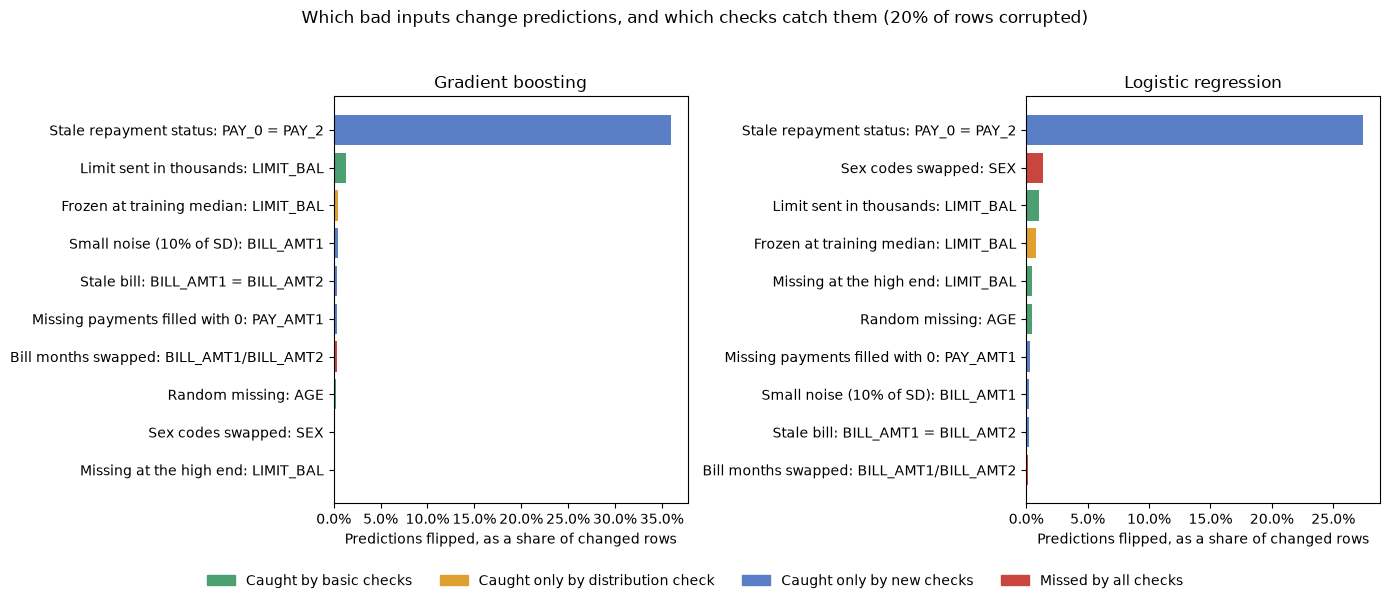

In [50]:
COLOURS = {
    "Caught by basic checks": "#4C9F70",
    "Caught only by distribution check": "#E0A030",
    "Caught only by new checks": "#5B7FC7",
    "Missed by all checks": "#C8463D",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, MODELS):
    data = summary[summary["model"] == name].sort_values("flip_rate_corrupted")
    ax.barh(data["corruption"], data["flip_rate_corrupted"], color=data["detection"].map(COLOURS))
    ax.set_title(name.replace("_", " ").capitalize())
    ax.set_xlabel("Predictions flipped, as a share of changed rows")
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLOURS.values()]
fig.legend(handles, COLOURS.keys(), loc="lower center", ncol=4, frameon=False)
fig.suptitle("Which bad inputs change predictions, and which checks catch them (20% of rows corrupted)")
fig.tight_layout(rect=(0, 0.06, 1, 0.95))
fig.savefig(OUTPUT_DIR / "impact_vs_detection.png", dpi=200)
plt.show()

## 10. Before you write it up

- **Check the danger zone.** Did the new checks catch the stale repayment status? Look at `detection_by_severity.csv`: from what severity does each check fire?
- **Read the direction table.** If most flips for stale data go *to low risk*, the error hides customers who recently fell behind. That's the costliest direction for a lender.
- **Watch for false alarms.** Both new checks passed on clean test data (the sanity checks above). Thresholds trade missed errors against false alarms; `Z_THRESHOLD` and `PREDICTION_PSI_THRESHOLD` are deliberately conservative. Report them.
- **Know the limits of each check.** The consistency check only covers the column pairs in `PAIRS`. Prediction drift can stay quiet when errors push predictions both ways and cancel out in the overall distribution.
- **Sanity-check surprises.** If a corruption barely changes predictions, check that feature's importance before concluding the error doesn't matter.
- **Scope your claims.** One dataset, two models, these corruptions, one threshold (`THRESHOLD = 0.5`). Say so.
- **Credit the data:** Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H (CC BY 4.0).